# 05 — In-depth results analysis and answer to the research question

This notebook brings together the audit, descriptive analysis, uncertainty calculations, model evaluation, and business interpretation. It reads saved artifacts rather than recomputing or manually copying results. The goal is to answer: **what factors most strongly predict whether an online visitor makes a purchase?**

The answer must distinguish three ideas: descriptive association, predictive contribution in the fitted model, and causation. This project estimates the first two; it does not establish the third.

In [1]:
import sys
from pathlib import Path
_base = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(_base))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import ROOT

T = ROOT / 'reports/tables'; F = ROOT / 'reports/figures'
required = ['split_summary.csv', 'visitor_conversion_training.csv', 'visitor_bootstrap_difference.csv', 'numeric_target_comparisons_training.csv', 'model_metrics.csv', 'selected_threshold.csv', 'validation_grouped_permutation_importance.csv', 'pagevalues_sensitivity_metrics.csv']
missing = [name for name in required if not (T / name).exists()]
if missing: raise FileNotFoundError(f'Run notebooks 01–04 first: {missing}')
splits = pd.read_csv(T / 'split_summary.csv')
visitors = pd.read_csv(T / 'visitor_conversion_training.csv')
bootstrap = pd.read_csv(T / 'visitor_bootstrap_difference.csv').iloc[0]
numeric = pd.read_csv(T / 'numeric_target_comparisons_training.csv')
metrics = pd.read_csv(T / 'model_metrics.csv')
threshold = pd.read_csv(T / 'selected_threshold.csv').iloc[0]
importance = pd.read_csv(T / 'validation_grouped_permutation_importance.csv')
sensitivity = pd.read_csv(T / 'pagevalues_sensitivity_metrics.csv')
sessions = int(splits.sessions.sum()); purchases = int(splits.purchases.sum())
print(f'{sessions:,} sessions; {purchases:,} purchases; overall conversion {purchases/sessions:.2%}')

12,330 sessions; 1,908 purchases; overall conversion 15.47%


## Evidence overview

The first visual compares the main descriptive conversion difference, the leading validation permutation contributions, and the primary model's test performance relative to the prevalence baseline. The scales are deliberately separated so that percentages, average-precision decreases, and model metrics are not incorrectly treated as the same unit.

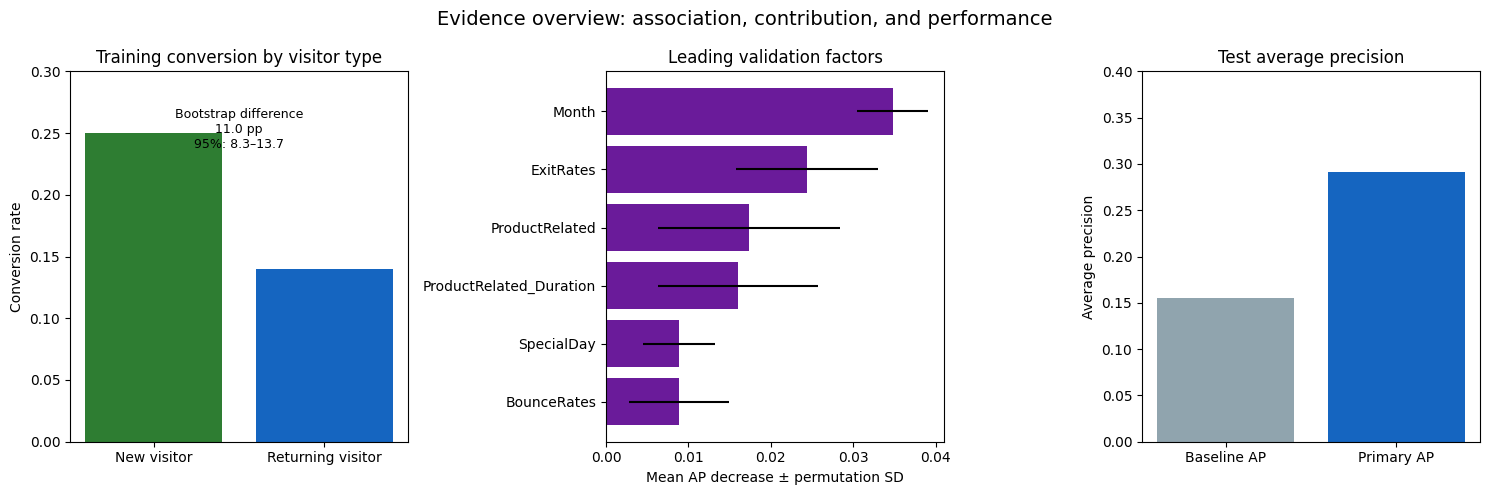

In [2]:
from IPython.display import display
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].bar(['New visitor', 'Returning visitor'], [visitors.loc[visitors.group.eq('New_Visitor'), 'conversion_rate'].iloc[0], visitors.loc[visitors.group.eq('Returning_Visitor'), 'conversion_rate'].iloc[0]], color=['#2e7d32', '#1565c0'])
axes[0].set_title('Training conversion by visitor type'); axes[0].set_ylabel('Conversion rate'); axes[0].set_ylim(0, .3)
axes[0].text(.5, .27, f"Bootstrap difference\n{bootstrap.difference_percentage_points:.1f} pp\n95%: {bootstrap.bootstrap_ci_low_percentage_points:.1f}–{bootstrap.bootstrap_ci_high_percentage_points:.1f}", ha='center', va='top', fontsize=9)
top = importance.head(6).sort_values('mean_ap_decrease')
axes[1].barh(top.feature, top.mean_ap_decrease, xerr=top.sd_ap_decrease, color='#6a1b9a'); axes[1].set_title('Leading validation factors'); axes[1].set_xlabel('Mean AP decrease ± permutation SD')
test_metrics = metrics[metrics.split.eq('test')].sort_values('threshold').drop_duplicates('model').set_index('model')
axes[2].bar(['Baseline AP', 'Primary AP'], [test_metrics.loc['training_prevalence', 'average_precision'], test_metrics.loc['primary_logistic', 'average_precision']], color=['#90a4ae', '#1565c0']); axes[2].set_ylim(0, .4); axes[2].set_title('Test average precision'); axes[2].set_ylabel('Average precision')
fig.suptitle('Evidence overview: association, contribution, and performance', fontsize=14); fig.tight_layout(); fig.savefig(F / '18_in_depth_evidence_overview.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

## What the descriptive analysis says

New visitors converted at **25.02%** (251 of 1,003 training sessions), while returning visitors converted at **13.98%** (886 of 6,338). The seeded 2,000-replicate within-group bootstrap estimated an **11.05 percentage-point** difference with a 95% interval of **8.34–13.70 points**. This is a robust descriptive contrast in this sample, but it does not show that changing visitor classification would cause conversion.

Product-related page counts and durations were also higher in purchasing sessions, while ExitRates and BounceRates were lower in purchasing sessions. These variables summarize the session and may be measured after much of the purchase journey has already happened. They are useful for retrospective understanding, not automatically valid early intervention signals.

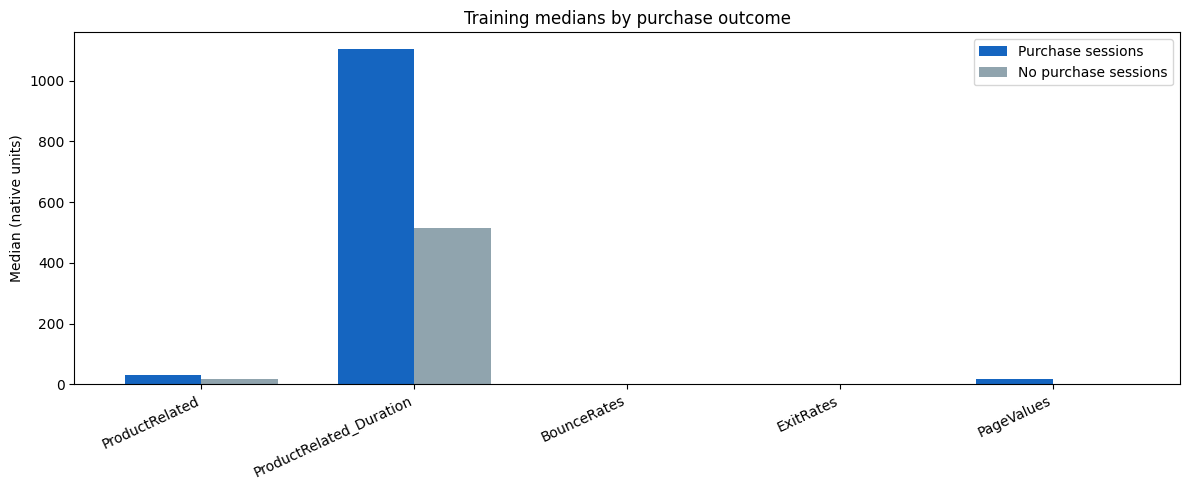

In [3]:
from IPython.display import display
plot_features = ['ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues']
plot_data = numeric[numeric.feature.isin(plot_features)].copy().set_index('feature').loc[plot_features].reset_index()
x = np.arange(len(plot_data)); width = .36
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x-width/2, plot_data.purchase_median, width, label='Purchase sessions', color='#1565c0')
ax.bar(x+width/2, plot_data.nonpurchase_median, width, label='No purchase sessions', color='#90a4ae')
ax.set_xticks(x, plot_data.feature, rotation=25, ha='right'); ax.set_ylabel('Median (native units)'); ax.set_title('Training medians by purchase outcome'); ax.legend()
fig.tight_layout(); fig.savefig(F / '19_numeric_outcome_medians.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

## What the predictive model says

The primary PageValues-excluded logistic model achieved test average precision **0.291**, ROC AUC **0.722**, and log loss **0.393**, compared with average precision **0.155** and log loss **0.432** for the training-prevalence baseline. The validation-selected threshold was **0.1717**, producing test F1 **0.372**. Average precision is emphasized because purchases are the minority class; accuracy alone would be misleading.

Grouped permutation importance ranked **Month**, **ExitRates**, **ProductRelated**, and **ProductRelated_Duration** highest, with mean AP decreases of 0.035, 0.024, 0.017, and 0.016. These rankings describe predictive contribution in this fitted model and validation sample. Correlation and shared information can cause importance to be divided among related predictors.

The PageValues sensitivity model performed better (test average precision **0.588**, log loss **0.329**), but PageValues is transaction-linked and its timing is not established. That improvement should be interpreted as a leakage/timing sensitivity result, not a deployable targeting recommendation.

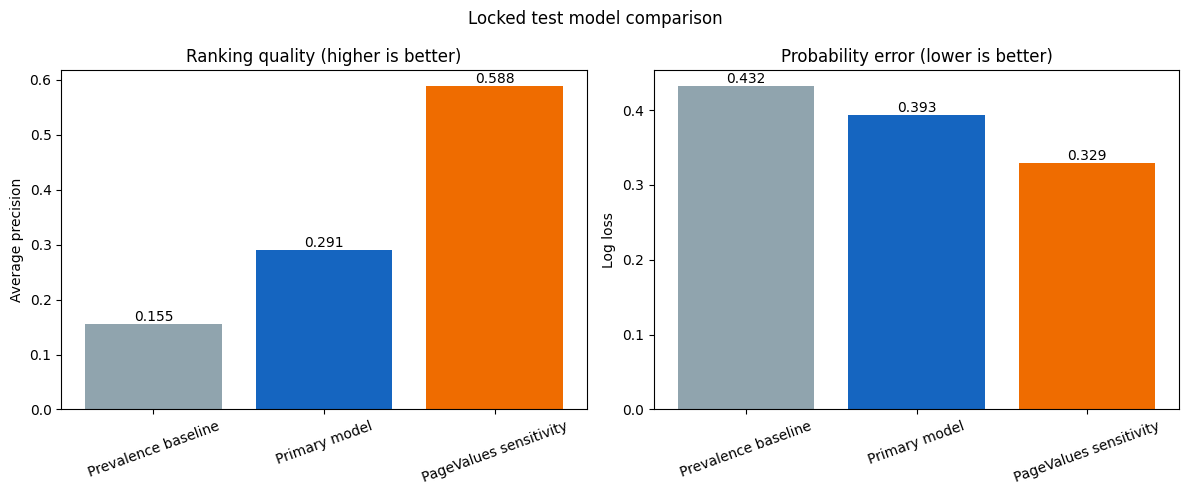

In [4]:
from IPython.display import display
primary = metrics[(metrics.model.eq('primary_logistic')) & (metrics.split.eq('test')) & (metrics.threshold.round(6).eq(round(float(threshold.threshold), 6)))].iloc[0]
pv = sensitivity[sensitivity.split.eq('test')].iloc[0]
comparison = pd.DataFrame({'Model': ['Prevalence baseline', 'Primary model', 'PageValues sensitivity'], 'Average precision': [test_metrics.loc['training_prevalence', 'average_precision'], primary.average_precision, pv.average_precision], 'Log loss': [test_metrics.loc['training_prevalence', 'log_loss'], primary.log_loss, pv.log_loss]})
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, metric, title in zip(axes, ['Average precision', 'Log loss'], ['Ranking quality (higher is better)', 'Probability error (lower is better)']):
    bars=ax.bar(comparison['Model'], comparison[metric], color=['#90a4ae','#1565c0','#ef6c00']); ax.set_title(title); ax.set_ylabel(metric); ax.tick_params(axis='x', rotation=20)
    for bar, value in zip(bars, comparison[metric]): ax.text(bar.get_x()+bar.get_width()/2, value, f'{value:.3f}', ha='center', va='bottom')
fig.suptitle('Locked test model comparison'); fig.tight_layout(); fig.savefig(F / '20_in_depth_model_comparison.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

## Clear answer to the research question

**The strongest predictive factors in this analysis are Month, ExitRates, ProductRelated, and ProductRelated_Duration, based on validation grouped permutation importance in the PageValues-excluded model.** Visitor type is also an important descriptive segment: new visitors converted more often than returning visitors in the training data. The primary model improves on a prevalence baseline, so the included session characteristics provide useful retrospective ranking signal.

This answer is intentionally qualified. It means these factors contributed most to predictions for this sample and model; it does not mean they are the strongest causes of purchase, that increasing page counts or duration will increase conversion, or that all factors are available before a session ends. The appropriate business next step is randomized testing of new-visitor onboarding, product-information presentation, and carefully predeclared seasonal or checkout-friction hypotheses, with conversion as the outcome and usability guardrails. No ROI or conversion lift can be claimed from this dataset.

## Limitations

This is one historical dataset of summarized sessions. It has no prices, costs, profit, customer histories, event-level sequences, or confirmed live feature timing. The target is imbalanced, some segments are small, predictors are correlated, and the model is not externally validated. The PageValues sensitivity model demonstrates why timing and leakage checks matter. The findings support prioritizing hypotheses, not deployment or causal business claims.